<a href="https://colab.research.google.com/github/susan-awori/Data-processing/blob/main/Copy_of_01_Linear_Regression_with_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

___

<a href='http://www.pieriandata.com'> <img src='../Pierian_Data_Logo.png' /></a>
___
# Linear Regression with Python

** This is mostly just code for reference. Please watch the video lecture for more info behind all of this code.**

Your neighbor is a real estate agent and wants some help predicting housing prices for regions in the USA. It would be great if you could somehow create a model for her that allows her to put in a few features of a house and returns back an estimate of what the house would sell for.

She has asked you if you could help her out with your new data science skills. You say yes, and decide that Linear Regression might be a good path to solve this problem!

Your neighbor then gives you some information about a bunch of houses in regions of the United States,it is all in the data set: USA_Housing.csv.

The data contains the following columns:

* 'Avg. Area Income': Avg. Income of residents of the city house is located in.
* 'Avg. Area House Age': Avg Age of Houses in same city
* 'Avg. Area Number of Rooms': Avg Number of Rooms for Houses in same city
* 'Avg. Area Number of Bedrooms': Avg Number of Bedrooms for Houses in same city
* 'Area Population': Population of city house is located in
* 'Price': Price that the house sold at
* 'Address': Address for the house

**Let's get started!**
## Check out the data
We've been able to get some data from your neighbor for housing prices as a csv set, let's get our environment ready with the libraries we'll need and then import the data!
### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### Check out the Data

In [2]:
USAhousing = pd.read_csv('USA_Housing.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'USA_Housing.csv'

In [ ]:
import kagglehub
path = kagglehub.dataset_download("quantbruce/real-estate-price-prediction")
print(path)

In [ ]:
real_estate = pd.read_csv(f'{path}/Real estate.csv')
real_estate.head()

In [ ]:
USAhousing.head()

In [ ]:
USAhousing.info()

In [ ]:
USAhousing.describe()

In [ ]:
USAhousing.columns

# EDA

Let's create some simple plots to check out the data!

In [ ]:
sns.pairplot(USAhousing)

In [ ]:
sns.distplot(USAhousing['Price'])

In [ ]:
sns.heatmap(USAhousing.corr(numeric_only = True),annot =True)

## Training a Linear Regression Model

Let's now begin to train out regression model! We will need to first split up our data into an X array that contains the features to train on, and a y array with the target variable, in this case the Price column. We will toss out the Address column because it only has text info that the linear regression model can't use.

### X and y arrays

In [ ]:
#X = USAhousing[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
#               'Avg. Area Number of Bedrooms', 'Area Population']]
X = USAhousing[['Avg. Area Income','Avg. Area House Age', 'Area Population']]
y = USAhousing['Price']

## Train Test Split

Now let's split the data into a training set and a testing set. We will train out model on the training set and then use the test set to evaluate the model.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=101)

In [ ]:
X_train.shape

In [ ]:
y_train.shape

In [ ]:
X_test.shape

## Creating and Training the Model

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lm = LinearRegression()

In [ ]:
lm.fit(X_train,y_train)

## Model Evaluation

Let's evaluate the model by checking out it's coefficients and how we can interpret them.

In [ ]:
# print the intercept
print(lm.intercept_)

In [ ]:
coeff_df = pd.DataFrame(lm.coef_,X.columns,columns=['Coefficient'])
coeff_df

In [ ]:
x1 = 75000
x2 = 5
x3 =  1000
y = (21.25 * x1)+(163727.47 * x2) + (15.30 * x3)-1756415.02
y

Interpreting the coefficients:

- Holding all other features fixed, a 1 unit increase in **Avg. Area Income** is associated with an **increase of \$21.52 **.
- Holding all other features fixed, a 1 unit increase in **Avg. Area House Age** is associated with an **increase of \$164883.28 **.
- Holding all other features fixed, a 1 unit increase in **Avg. Area Number of Rooms** is associated with an **increase of \$122368.67 **.
- Holding all other features fixed, a 1 unit increase in **Avg. Area Number of Bedrooms** is associated with an **increase of \$2233.80 **.
- Holding all other features fixed, a 1 unit increase in **Area Population** is associated with an **increase of \$15.15 **.

Does this make sense? Probably not because I made up this data. If you want real data to repeat this sort of analysis, check out the [boston dataset](http://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_boston.html):



    from sklearn.datasets import load_boston
    boston = load_boston()
    print(boston.DESCR)
    boston_df = boston.data

## Predictions from our Model

Let's grab predictions off our test set and see how well it did!

In [ ]:
predictions = lm.predict(X_test)

In [ ]:
plt.scatter(y_test,predictions)

**Residual Histogram**

In [ ]:
sns.distplot((y_test-predictions),bins=50);

## Regression Evaluation Metrics


Here are three common evaluation metrics for regression problems:

**Mean Absolute Error** (MAE) is the mean of the absolute value of the errors:

$$\frac 1n\sum_{i=1}^n|y_i-\hat{y}_i|$$

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

Comparing these metrics:

- **MAE** is the easiest to understand, because it's the average error.
- **MSE** is more popular than MAE, because MSE "punishes" larger errors, which tends to be useful in the real world.
- **RMSE** is even more popular than MSE, because RMSE is interpretable in the "y" units.

All of these are **loss functions**, because we want to minimize them.

In [ ]:
from sklearn import metrics

In [ ]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', metrics.root_mean_squared_error(y_test, predictions))

This was your first real Machine Learning Project! Congrats on helping your neighbor out! We'll let this end here for now, but go ahead and explore the Boston Dataset mentioned earlier if this particular data set was interesting to you!

Up next is your own Machine Learning Project!

## Great Job!

# Polynomial regression

In [5]:
from IPython.core import usage
import pandas as pd
real_estate = pd.read_csv('Real estate.csv')

In [6]:
real_estate.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [7]:
real_estate.tail()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5
413,414,2013.500,6.5,90.45606,9,24.97433,121.54310,63.9


In [8]:
real_estate.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

In [9]:
X = real_estate[['X2 house age','X3 distance to the nearest MRT station']]
y = real_estate['Y house price of unit area']

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import PolynomialFeatures

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [12]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

In [13]:
y_pred = linear_model.predict(X_test)

In [14]:
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred,'Loss':(y_pred-y_test)})
comparison_df.head()

,Actual,Predicted,Loss
176,19.2,12.469594,-6.730406
347,11.2,-2.949483,-14.149483
307,24.7,24.729947,0.029947
299,46.1,41.153165,-4.946835
391,31.3,34.440848,3.140848


In [15]:
y_pred2 = linear_model.predict(X_test)
comparison_df2 = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred2,'Loss':(y_pred2-y_test)})
comparison_df2.head()

,Actual,Predicted,Loss
176,19.2,12.469594,-6.730406
347,11.2,-2.949483,-14.149483
307,24.7,24.729947,0.029947
299,46.1,41.153165,-4.946835
391,31.3,34.440848,3.140848


In [16]:
r2 = metrics.r2_score(y_test, y_pred)
rmse = metrics.root_mean_squared_error(y_test, y_pred)
print(f'The model\'s r^2 is {r2} & the rmse is {rmse}')

The model's r^2 is 0.5235827838437671 & the rmse is 7.39236443398342


In [17]:
r2_2 = metrics.r2_score(y_test, y_pred2)
rmse2 = metrics.root_mean_squared_error(y_test, y_pred2)
print(f'The model\'s r^2 is {r2} & the rmse is {rmse}')

The model's r^2 is 0.5235827838437671 & the rmse is 7.39236443398342


In [18]:
results = {}
for degree in range(2,10):
    poly_features = PolynomialFeatures(degree=degree)
    X_poly = poly_features.fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=101)
    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)
    y_pred_train = poly_model.predict(X_train)
    r2_train= metrics.r2_score(y_train, y_pred_train)
    rmse_train = metrics.root_mean_squared_error(y_train, y_pred_train)
    y_pred = poly_model.predict(X_test)
    r2_test = metrics.r2_score(y_test, y_pred)
    rmse_test = metrics.root_mean_squared_error(y_test, y_pred)
    results[degree] = {
        'model': poly_model,
        'r2_train': r2_train,
        'rmse_train': rmse_train,
        'r2_test': r2_test,
        'rmse_test': rmse_test,
    }


pd.DataFrame(results).T


,model,r2_train,rmse_train,r2_test,rmse_test
2,LinearRegression(),0.586022,9.14995,0.636472,6.45741
3,LinearRegression(),0.606389,8.922031,0.692675,5.937298
4,LinearRegression(),0.61513,8.822418,0.700506,5.861161
5,LinearRegression(),0.609868,8.882518,0.323293,8.810288
6,LinearRegression(),0.473822,10.315648,-0.065855,11.057038
7,LinearRegression(),0.378426,11.211839,-6.133603,28.605142
8,LinearRegression(),0.299462,11.902721,-24.570509,54.157591
9,LinearRegression(),0.234682,12.440887,-26.736814,56.405042


In [19]:
results = {}
for degree in range(2,10):
    poly_features = PolynomialFeatures(degree=degree)
    X_poly = poly_features.fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=101)
    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)
    y_pred_train = poly_model.predict(X_train)
    r2_train= metrics.r2_score(y_train, y_pred_train)
    rmse_train = metrics.root_mean_squared_error(y_train, y_pred_train)
    y_pred = poly_model.predict(X_test)
    r2_test = metrics.r2_score(y_test, y_pred)
    rmse_test = metrics.root_mean_squared_error(y_test, y_pred)
    results[degree] = {
        'model': poly_model,
        'r2_train': r2_train,
        'rmse_train': rmse_train,
        'r2_test': r2_test,
        'rmse_test': rmse_test,
    }


pd.DataFrame(results).T


,model,r2_train,rmse_train,r2_test,rmse_test
2,LinearRegression(),0.586022,9.14995,0.636472,6.45741
3,LinearRegression(),0.606389,8.922031,0.692675,5.937298
4,LinearRegression(),0.61513,8.822418,0.700506,5.861161
5,LinearRegression(),0.609868,8.882518,0.323293,8.810288
6,LinearRegression(),0.473822,10.315648,-0.065855,11.057038
7,LinearRegression(),0.378426,11.211839,-6.133603,28.605142
8,LinearRegression(),0.299462,11.902721,-24.570509,54.157591
9,LinearRegression(),0.234682,12.440887,-26.736814,56.405042


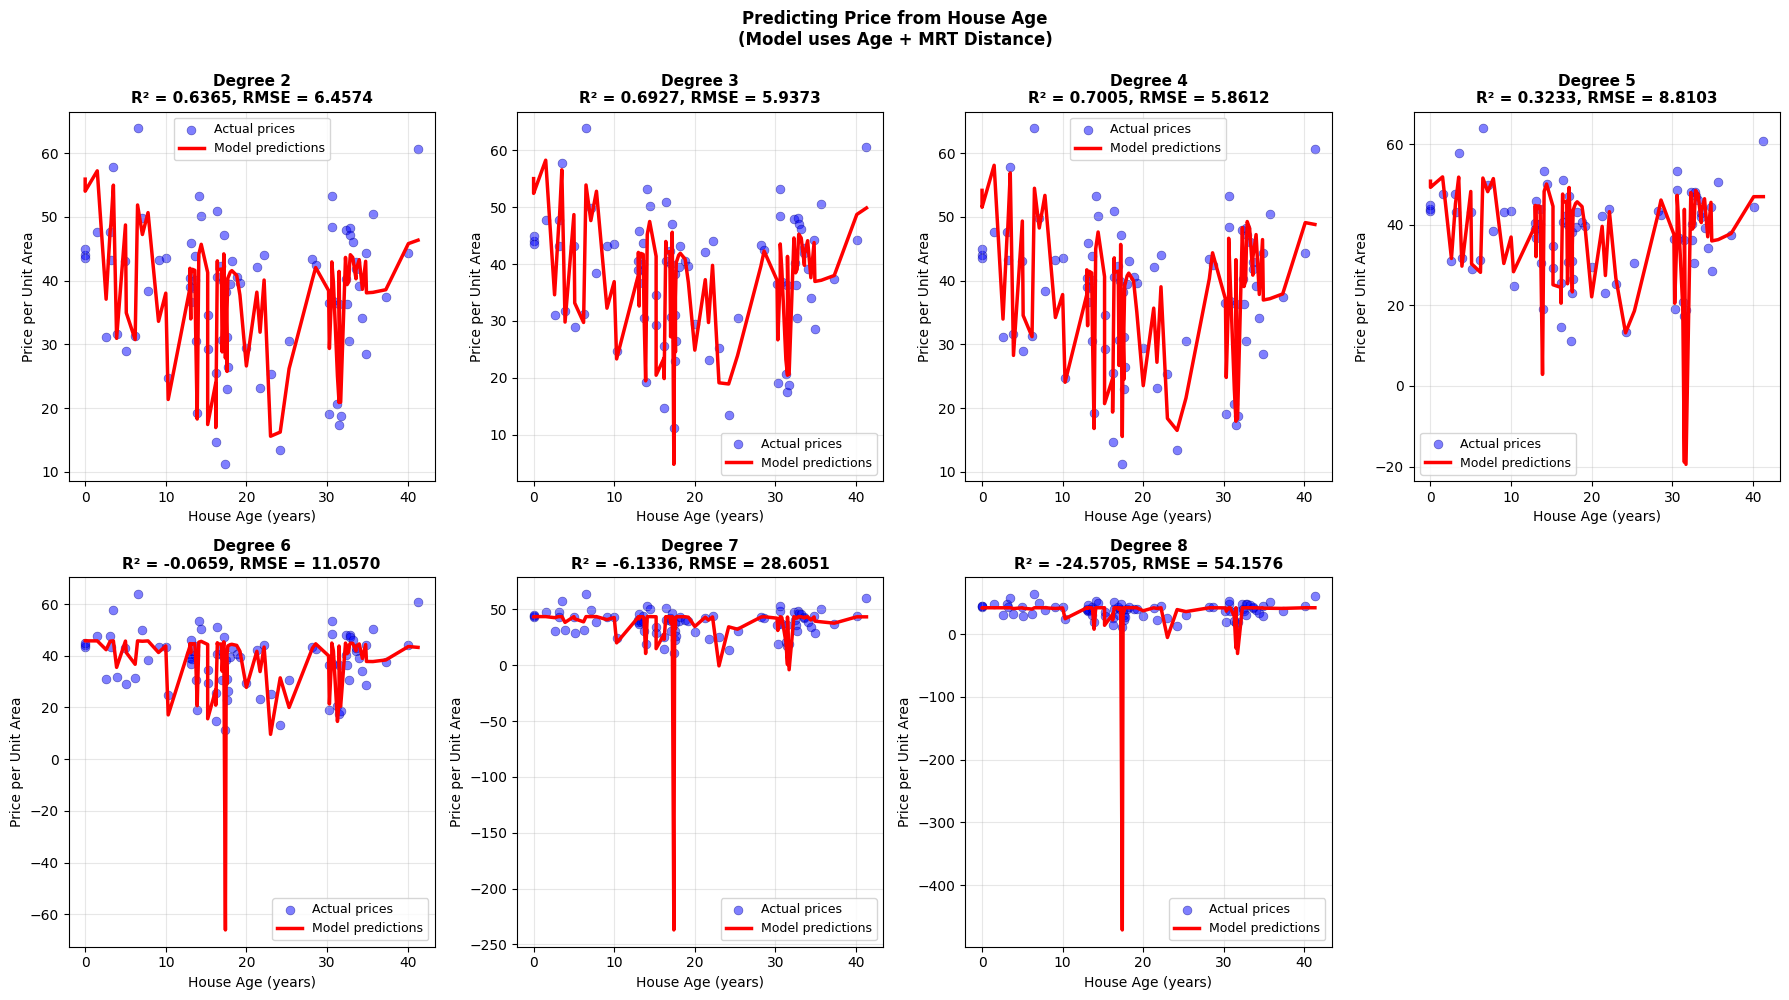

In [28]:
# 1. Re-train the polynomial models and store the poly_features transformers so they can be reused for predictions
results = {}
for degree in range(2, 10):
    poly_features = PolynomialFeatures(degree=degree)
    # Fit and transform the original 2-feature DataFrame X
    X_poly = poly_features.fit_transform(X)
    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_poly, y, test_size=0.2, random_state=101)

    poly_model = LinearRegression()
    poly_model.fit(X_train_p, y_train_p)

    y_pred_train = poly_model.predict(X_train_p)
    r2_train = metrics.r2_score(y_train_p, y_pred_train)
    rmse_train = metrics.root_mean_squared_error(y_train_p, y_pred_train)

    y_pred_test = poly_model.predict(X_test_p)
    r2_test = metrics.r2_score(y_test_p, y_pred_test)
    rmse_test = metrics.root_mean_squared_error(y_test_p, y_pred_test)

    results[degree] = {
        'poly_features': poly_features,
        'model': poly_model,
        'r2_train': r2_train,
        'rmse_train': rmse_train,
        'r2_test': r2_test,
        'rmse_test': rmse_test,
    }

# Get the original split of X to extract house age correctly for plotting
_, X_test_orig, _, y_test_orig = train_test_split(X, y, test_size=0.2, random_state=101)

# Now run the visualization
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

degrees_to_plot = [2, 3, 4, 5, 6, 7, 8]

for idx, degree in enumerate(degrees_to_plot):
    ax = axes[idx]

    # Extract just the house age column (first feature of X) for plotting on the x-axis
    X_test_age = X_test_orig.iloc[:, 0].values if hasattr(X_test_orig, 'iloc') else X_test_orig[:, 0]

    # Use the STORED poly_features transformer
    poly = results[degree]['poly_features']
    X_test_poly = poly.transform(X_test_orig)

    # Get the model and predict
    model = results[degree]['model']
    y_pred_test = model.predict(X_test_poly)

    # Sort by age for cleaner line plot
    sort_idx = np.argsort(X_test_age)
    X_test_age_sorted = X_test_age[sort_idx]
    y_test_sorted = y_test_orig.values[sort_idx] if hasattr(y_test_orig, 'values') else y_test_orig[sort_idx]
    y_pred_sorted = y_pred_test[sort_idx]

    # Plot actual vs predicted
    ax.scatter(X_test_age_sorted, y_test_sorted, alpha=0.5, s=40,
               label='Actual prices', color='blue', edgecolors='navy', linewidth=0.5)
    ax.plot(X_test_age_sorted, y_pred_sorted, 'r-', linewidth=2.5,
            label='Model predictions')

    # Get metrics
    test_r2 = results[degree]['r2_test']
    test_rmse = results[degree]['rmse_test']

    ax.set_title(f'Degree {degree}\nR² = {test_r2:.4f}, RMSE = {test_rmse:.4f}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('House Age (years)', fontsize=10)
    ax.set_ylabel('Price per Unit Area', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the extra empty subplot
axes[-1].axis('off')

plt.suptitle('Predicting Price from House Age\n(Model uses Age + MRT Distance)',
             fontsize=12, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('polynomial_comparison.png', dpi=150, bbox_inches='tight')
plt.show()